# Artificial Intelligence in Health Care - Exercise 2
## Convolutional Neural Networks for Image Classification

Mitglieder: Elbischger Selina, Krauss Marco
Jahrgang: EHT25

Das Ziel der Übung ist es ein CNN (Convolusional neural Network) zu trainieren um damit verschiedene histologische Bilder von Darmgewebe der passenden Kategorie (Darmschleimhaut, Tumorgewebe, Muskel, etc. ) zuordnen zu können.

In [5]:
#Imports and Configs
import os
os.environ["KERAS_BACKEND"] = "torch"

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

warnings.filterwarnings("ignore")
SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3})
print("keras", keras.__version__, "| backend", keras.backend.backend())

keras 3.15.1 | backend torch


## Datenimport

In [6]:
import numpy as np
data = np.load(os.path.join(ordner, "path_train.npz"))
print(list(data.keys()))

x_train, y_train = data["x_train"], data["y_train"]
x_val,   y_val   = data["x_val"],   data["y_val"]
x_test,  y_test  = data["x_test"],  data["y_test"]

#Kontrolle mit Angabenzettel Anzahl der Daten
print(x_train.shape, x_val.shape, x_test.shape)

['x_train', 'x_val', 'x_test', 'y_train', 'y_val', 'y_test']
(89996, 28, 28, 3) (10004, 28, 28, 3) (5744, 28, 28, 3)


### 1 Data Pre-Processing and Partitioning [2P]:


Make yourself familiar with the dataset by plotting one example image per class, arranged in
a figure of e.g. two rows, including class names and labels. Prepare class labels for the use
with a neural network and multi-class classification. The images are given in a range of [0, 255];
normalise them to [0, 1]. Report the class distribution of the training set. You will need it when
you interpret the confusion matrix in tasks 2 and 3.

#### Labels in 1D Array, Klassennamen festlegen 

In [7]:
#In 1D Arrays umwandeln, da Keras sonst Probleme hat
y_train = y_train.ravel(); y_val = y_val.ravel(); y_test = y_test.ravel()  

#Klassen aus Angabe übernommen, da die Klassenbezeichnungen nicht importiert wird wie bei medmnist
CLASSES = ["ADI", "BACK", "DEB", "LYM", "MUC", "MUS", "NORM", "STR", "TUM"]


#### Beispielbild pro Klasse

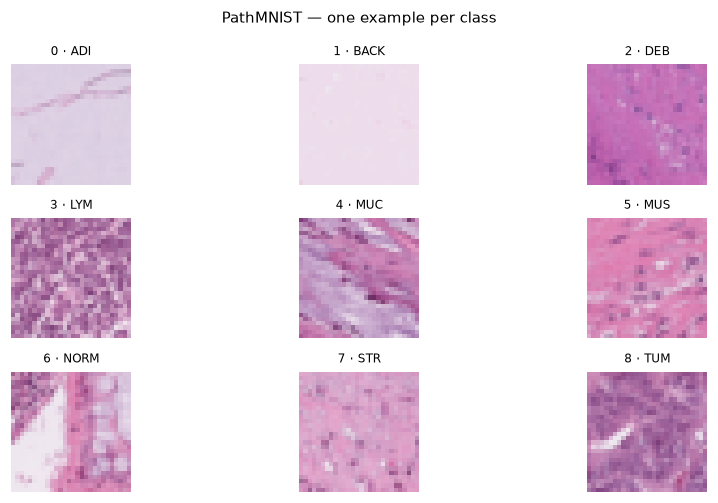

In [8]:

fig, axes = plt.subplots(3, 3, figsize=(9, 4.6))
for i, ax in enumerate(axes.ravel()):
        ax.imshow(x_train[np.where(y_train == i)[0][0]])
        ax.set_title(f"{i} · {CLASSES[i]}", fontsize=8)
        ax.axis("off")
fig.suptitle("PathMNIST — one example per class", fontsize=10)
plt.tight_layout(); plt.show()


#### Klassenverteilung y_train

In [9]:
#Ausgabe der Datensatzgrößen und Klassenverteilung
print("train / val / test:", len(y_train), len(y_val), len(y_test))
print("image shape       :", x_train.shape[1:])
print("classes           :", len(CLASSES))
for i, c in enumerate(CLASSES):
    print(f"  {i}  {c:<28} {(y_train==i).sum():>6} {100*(y_train==i).mean():>5.1f}%")
print()
print("majority-class baseline accuracy: %.3f" % (np.bincount(y_test).max()/len(y_test)))

train / val / test: 89996 10004 5744
image shape       : (28, 28, 3)
classes           : 9
  0  ADI                            9366  10.4%
  1  BACK                           9509  10.6%
  2  DEB                           10360  11.5%
  3  LYM                           10401  11.6%
  4  MUC                            8006   8.9%
  5  MUS                           12182  13.5%
  6  NORM                           7886   8.8%
  7  STR                            9401  10.4%
  8  TUM                           12885  14.3%

majority-class baseline accuracy: 0.186


#### Bilder auf [0, 1] normalisieren

In [10]:
#auf 0-1 normalisieren wie bei NB3
x_train = x_train.astype("float32") / 255.0
x_val   = x_val.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

#Check min und max wert, sollte 0 und 1 sein
print(x_train.min(), x_train.max())   

0.0 1.0


#### Labels One-Hot-kodieren

In [11]:
#pklassenlabels für One-Hot-Encoding vorbereiten
num_classes = len(CLASSES)

y_train_oh = keras.utils.to_categorical(y_train, num_classes)
y_val_oh   = keras.utils.to_categorical(y_val,   num_classes)
y_test_oh  = keras.utils.to_categorical(y_test,  num_classes)

#checken, ob die One-Hot-Encoding rihtig funktioniert hat, erste 3 labels ausgeben und die Form des Arrays
print(y_train[:3]); 
print(y_train_oh[:3]); 
print(y_train_oh.shape)

[0 4 7]
[[1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0.]]
(89996, 9)


#### 2 Fully-Connected Neural Network [3P]:

First implement a dense neural network with 3 hidden layers (1024, 512 and 128 units) with
relu activation and an output layer using softmax activation. For training, use the categorical
cross-entropy loss, early stopping on the validation set V, and e.g. the Adam optimizer with an
initial learning rate of α = 0.001. Consider the use of Dropout layers.
In contrast to Exercise 1, the input data here are images. To pass them to a dense network,
flatten them in the input layer using keras.layers.Flatten. Plot the learning curves for the training and validation set (loss and accuracy). Evaluate the
classification performance (accuracy, confusion matrix, AUROC) on the test set. Report the
number of trainable parameters to compare it against the CNN.

In [13]:
def train_model(model, epochs=25, tag=""):
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss=keras.losses.CategoricalCrossentropy(),
                  metrics=[keras.metrics.CategoricalAccuracy(name="acc")])
    
    es = keras.callbacks.EarlyStopping(monitor="val_acc", mode="max",
                                       patience=5, restore_best_weights=True)
    
    h = model.fit(x_train, y_train_oh, validation_data=(x_val, y_val_oh), epochs=epochs,
                  batch_size=128, verbose=0, callbacks=[es])
    
    prob = model.predict(x_test, verbose=0)
    pred = prob.argmax(1) # argmax along the class dimension for each sample
    
    acc = accuracy_score(y_test, pred)
    auc = roc_auc_score(y_test, prob, multi_class="ovr", average="macro")
    n_par = model.count_params()
    print(f"{tag:<22} test accuracy {acc:.4f}   macro AUROC {auc:.4f}   "
          f"parameters {n_par:,}   epochs {len(h.history['loss'])}")
    return dict(tag=tag, model=model, hist=h, acc=acc, auc=auc, params=n_par,
                prob=prob, pred=pred)


keras.utils.set_random_seed(SEED)
dense = keras.Sequential([
    layers.Input(shape=(28, 28, 3)),
    layers.Flatten(),                      # 28*28*3 = 2352 numbers, geometry gone
    layers.Dense(1024, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(512, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(CLASSES), activation="softmax"),         # softmax statt logits
    ], name="dense")

res_dense = train_model(dense, tag="dense network")

dense network          test accuracy 0.4333   macro AUROC 0.8299   parameters 3,001,097   epochs 7


#### Lernkurve Dense

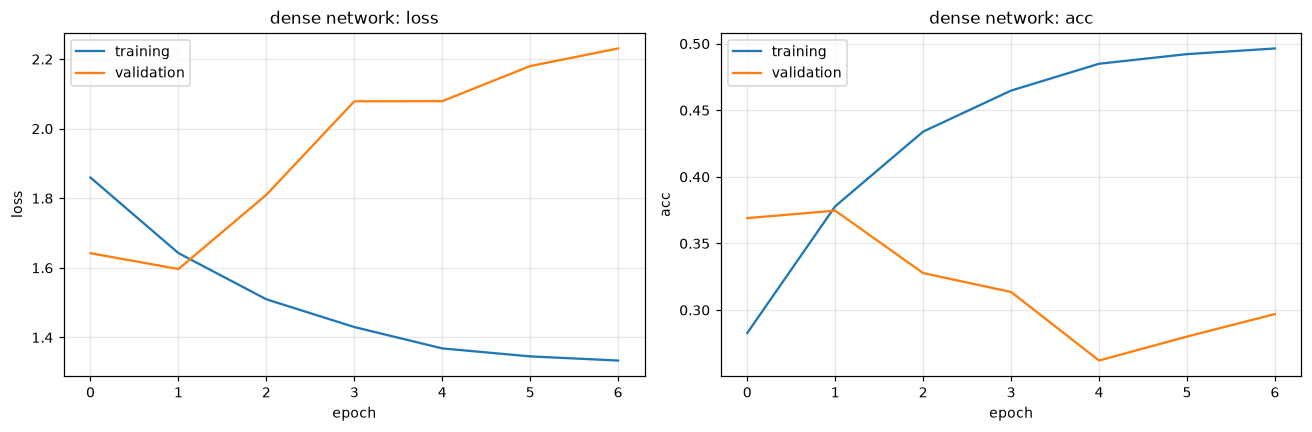

In [14]:
#Lernkurven (loss und acc)
h = res_dense["hist"].history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, m in enumerate(["loss", "acc"]):
    ax[i].plot(h[m], label="training")
    ax[i].plot(h[f"val_{m}"], label="validation")
    ax[i].set_xlabel("epoch"); ax[i].set_ylabel(m)
    ax[i].set_title(f"dense network: {m}"); ax[i].legend()
plt.tight_layout(); plt.show()

Die Lernkurven laufen nur in den ersten zwei Epochen mäßig parallel. Danach sinkt der Trainings-Loss weiter, während der Validierungs-Loss steigt: Das Netz overfittet vielleicht???. Das Early Stopping (auch wegen patience = 5) bricht deshalb nach 7 Epochen ab und stellt die Gewichte der besten Epoche wieder her = Epoch 2.

#### Confusion Matrix Dense TEST

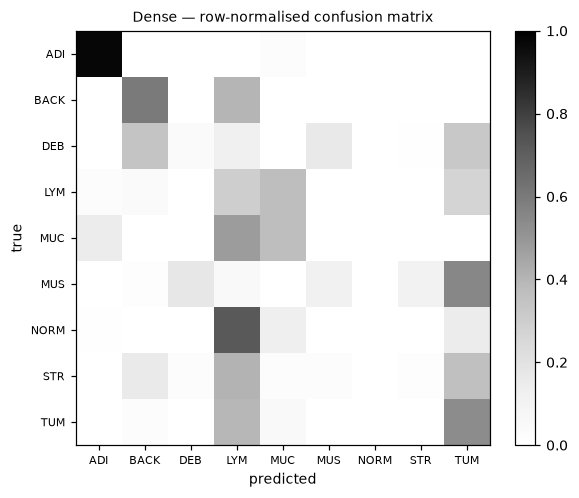

ADI   recall 0.975
BACK  recall 0.598
DEB   recall 0.041
LYM   recall 0.298
MUC   recall 0.371
MUS   recall 0.110
NORM  recall 0.000
STR   recall 0.014
TUM   recall 0.533


In [ ]:
cm = confusion_matrix(y_test, res_dense["pred"])
fig, ax = plt.subplots(figsize=(5.4, 4.6))
im = ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Greys", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES))); ax.set_yticks(range(len(CLASSES)))
ax.set_xticklabels(CLASSES, fontsize=7); ax.set_yticklabels(CLASSES, fontsize=7)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Test", fontsize=9)
ax.grid(False); plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

per_class = cm.diagonal() / cm.sum(1)
for c, r in zip(CLASSES, per_class):
    print(f"{c:<5} recall {r:.3f}")

dense network          test accuracy 0.4333   macro AUROC 0.8299   parameters 3,001,097   epochs 7



Das Dense-Netz erreicht auf dem Testset eine Accuracy von 43,3 % und eine AUROC von 0,83. Zuverlässig erkannt wird nur ADI (Recall 97,5 %). Die meisten Fehler landen bei LYM und TUM, während NORM, STR, DEB und MUS fast nie vorhergesagt werden. Vermutlich unterscheidet das Netz vor allem nach Farbe und Helligkeit. -> FETT!!!

### 3 Convolutional Neural Network [5P]:

Now implement a Convolutional Neural Network for classification of the 9 tissue types. In the
first stage use a convolutional architecture built from Conv2D and MaxPooling2D layers. In the
second stage use a fully-connected classification network. Do not forget to flatten the output of
the convolutional stage before passing it to the fully-connected part. Again use the categorical
cross-entropy loss and early stopping on V.
Plot the learning curves for the training and validation set. Evaluate the classification perfor-
mance (accuracy, confusion matrix, AUROC) on the test set. Try to achieve an accuracy as high
as possible (at least 70 %).
Summarise the performance measures from tasks 2 and 3 in a table and interpret the results.
Include the parameter count for both models and comment on what you find.

In [18]:
keras.utils.set_random_seed(SEED)
cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 3)),

    layers.Conv2D(32, 3, activation="relu", padding="same"), # Convolutional layer with 32 filters of size 3x3
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2),                # 28x28 -> 14x14

    layers.Conv2D(64, 3, activation="relu", padding="same"), # Convolutional layer with 64 filters of size 3x3
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2),                # 14x14 -> 7x7

    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(CLASSES), activation="softmax"), # softmax statt logits
], name="cnn")

cnn.summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,265 (1.79 MB)

 Trainable params: 468,265 (1.79 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
res_cnn = train_model(cnn, tag="convolutional network")

convolutional network  test accuracy 0.8748   macro AUROC 0.9870   parameters 468,265   epochs 23


Das CNN erreicht mit 87,5 % Accuracy und einer AUROC von 0,987 deutlich bessere Werte als das Dense-Netz (43,3 % bzw. 0,830), obwohl es mit rund 468 000 Parametern. Es gehen beim Flatten im Dense Netz geht die struktur also zusatzinfo verloren.

#### Lernkurve CNN

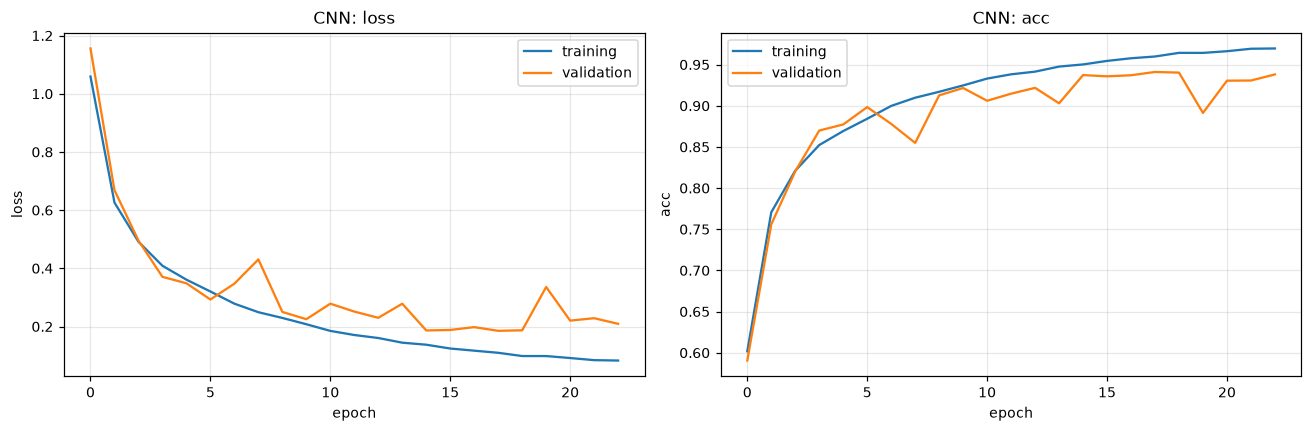

In [22]:
#Lernkurven CNN (loss und acc)
h = res_cnn["hist"].history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, m in enumerate(["loss", "acc"]):
    ax[i].plot(h[m], label="training")
    ax[i].plot(h[f"val_{m}"], label="validation")
    ax[i].set_xlabel("epoch"); ax[i].set_ylabel(m)
    ax[i].set_title(f"CNN: {m}"); ax[i].legend()
plt.tight_layout(); plt.show()

Training und Validierung verlaufen bis ca. Epoche 5 fast gleich. Ab ca. Epoche 10 stagniert der Validierungs-Loss, während der Trainings-Loss weiter sinkt (leichtes Overfitting). Das Early Stopping (patience = 5) bricht nach 23 Epochen ab und stellt die Gewichte von Epoche 18 wieder her.

#### confusion Matrix CNN

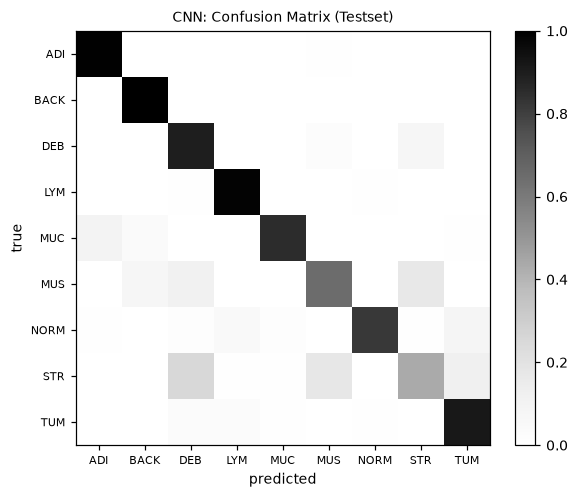

ADI   recall 0.993
BACK  recall 1.000
DEB   recall 0.896
LYM   recall 0.986
MUC   recall 0.854
MUS   recall 0.649
NORM  recall 0.820
STR   recall 0.435
TUM   recall 0.916


In [23]:
#Confusion Matrix CNN
cm_cnn = confusion_matrix(y_test, res_cnn["pred"])
fig, ax = plt.subplots(figsize=(5.4, 4.6))
im = ax.imshow(cm_cnn / cm_cnn.sum(1, keepdims=True), cmap="Greys", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES))); ax.set_yticks(range(len(CLASSES)))
ax.set_xticklabels(CLASSES, fontsize=7); ax.set_yticklabels(CLASSES, fontsize=7)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("CNN: Confusion Matrix (Testset)", fontsize=9)
ax.grid(False); plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

per_class_cnn = cm_cnn.diagonal() / cm_cnn.sum(1)
for c, r in zip(CLASSES, per_class_cnn):
    print(f"{c:<5} recall {r:.3f}")

Das CNN erkennt die meisten Klassen zuverlässig (Recall über 82 %). Am schwächsten sind STR (43,5 %) und MUS (64,9 %), die vor allem untereinander und mit DEB verwechselt werden. Stroma und Muskulatur sind beide faseriges, ähnlich gefärbtes Gewebe und bei dieser Auflösung schwer zu unterscheiden.

### Summary

In [24]:
#Vergleichstabelle Dense vs. CNN
results = [res_dense, res_cnn]
names = ["Dense-Netz", "CNN"]

table = pd.DataFrame({
    "Test-Accuracy": [r["acc"] for r in results],
    "Macro AUROC":   [r["auc"] for r in results],
    "Parameter":     [r["params"] for r in results],
    "Epochen":       [len(r["hist"].history["loss"]) for r in results],
}, index=names)

display(table.style.format({"Test-Accuracy": "{:.3f}", "Macro AUROC": "{:.3f}",
                            "Parameter": "{:,}"}))
print(f"Das CNN hat {res_dense['params'] / res_cnn['params']:.1f}x weniger Parameter")
print(f"Accuracy-Unterschied: {res_cnn['acc'] - res_dense['acc']:+.3f}")

,Test-Accuracy,Macro AUROC,Parameter,Epochen
Dense-Netz,0.433,0.830,"3,001,097",7
CNN,0.875,0.987,"468,265",23


Das CNN hat 6.4x weniger Parameter
Accuracy-Unterschied: +0.442


In [25]:
#Recall pro Klasse: Dense vs. CNN
cms = [confusion_matrix(y_test, r["pred"]) for r in results]

recall = pd.DataFrame({n: c.diagonal() / c.sum(1) for n, c in zip(names, cms)},
                      index=CLASSES)
recall["Differenz"] = recall["CNN"] - recall["Dense-Netz"]
display(recall.style.format("{:.3f}"))

,Dense-Netz,CNN,Differenz
ADI,0.975,0.993,0.019
BACK,0.598,1.000,0.402
DEB,0.041,0.896,0.855
LYM,0.298,0.986,0.688
MUC,0.371,0.854,0.484
MUS,0.110,0.649,0.539
NORM,0.000,0.820,0.820
STR,0.014,0.435,0.420
TUM,0.533,0.916,0.383


## BONUS EXTREME

In [28]:
#Augmentation: Drehung/Spiegelung + Farbveränderung (simuliert andere Färbung)
class AugmentedData(keras.utils.PyDataset):
    def __init__(self, x, y, batch_size=128, seed=0, **kwargs):
        super().__init__(**kwargs)
        self.x, self.y, self.bs = x, y, batch_size
        self.rng = np.random.default_rng(seed)
        self.idx = np.arange(len(x))
        self.rng.shuffle(self.idx)

    def __len__(self):
        return int(np.ceil(len(self.x) / self.bs))

    def __getitem__(self, i):
        b = self.idx[i * self.bs:(i + 1) * self.bs]
        xb = self.x[b].copy()
        n = len(xb)

        #Geometrie: zufällige 90°-Drehung und Spiegelung pro Bild
        for j in range(n):
            img = np.rot90(xb[j], self.rng.integers(4))
            if self.rng.random() < 0.5:
                img = img[:, ::-1]
            xb[j] = img

                #Farbe: jeder Kanal leicht verstärkt/verschoben (andere Färbung)
        xb = xb * self.rng.uniform(0.94, 1.06, (n, 1, 1, 3)) \
                + self.rng.uniform(-0.03, 0.03, (n, 1, 1, 3))
        #Kontrast
        mean = xb.mean(axis=(1, 2, 3), keepdims=True)
        xb = (xb - mean) * self.rng.uniform(0.85, 1.15, (n, 1, 1, 1)) + mean
        return np.clip(xb, 0, 1).astype("float32"), self.y[b]

    def on_epoch_end(self):
        self.rng.shuffle(self.idx)

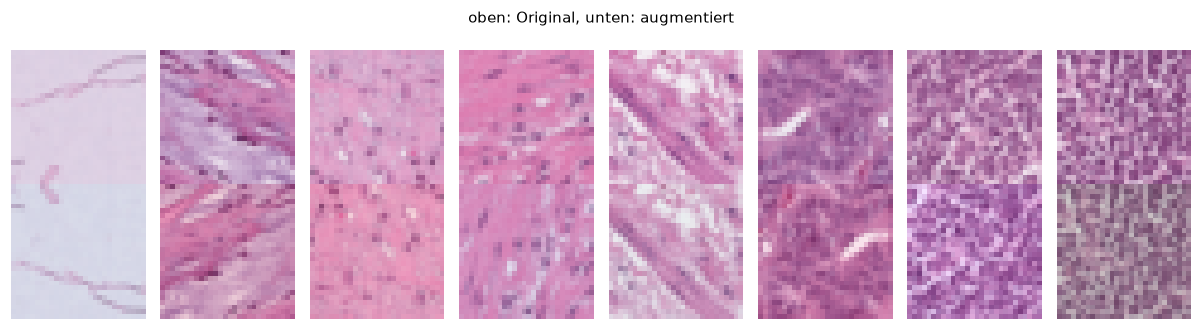

In [29]:
#Kontrolle: oben Original, unten augmentiert
demo = AugmentedData(x_train, y_train_oh, batch_size=8, seed=1)
demo.idx = np.arange(8)          #immer dieselben 8 Bilder zeigen
xb, _ = demo[0]
fig, axes = plt.subplots(2, 8, figsize=(11, 3))
for j in range(8):
    axes[0, j].imshow(x_train[j]); axes[0, j].axis("off")
    axes[1, j].imshow(xb[j]);      axes[1, j].axis("off")
fig.suptitle("oben: Original, unten: augmentiert", fontsize=10)
plt.tight_layout(); plt.show()

In [30]:
#Baustein aus NB3: zwei Conv-Schichten mit Batch Normalization, dann Pooling
def conv_block(x, n):
    x = layers.Conv2D(n, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(n, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    return layers.MaxPooling2D(2)(x)

def build_cnn(seed):
    keras.utils.set_random_seed(seed)
    inp = layers.Input(shape=(28, 28, 3))
    z = conv_block(inp, 32)                 # 28 -> 14
    z = conv_block(z, 64)                   # 14 -> 7
    z = conv_block(z, 128)                  # 7  -> 3
    z = layers.GlobalAveragePooling2D()(z)
    z = layers.Dropout(0.3)(z)
    out = layers.Dense(len(CLASSES), activation="softmax")(z)
    return keras.Model(inp, out, name=f"cnn_bonus_s{seed}")

def train_bonus(model, seed, epochs=60):
    model.compile(
        optimizer=keras.optimizers.AdamW(1e-3, weight_decay=1e-4),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
        metrics=[keras.metrics.CategoricalAccuracy(name="acc")])
    cbs = [keras.callbacks.EarlyStopping(monitor="val_acc", mode="max",
                                         patience=10, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                             patience=3, min_lr=1e-5)]
    return model.fit(AugmentedData(x_train, y_train_oh, seed=seed),
                     validation_data=(x_val, y_val_oh),
                     epochs=epochs, verbose=1, callbacks=cbs)

def evaluate(model, tag):
    prob = model.predict(x_test, verbose=0, batch_size=512)
    pred = prob.argmax(1)
    acc = accuracy_score(y_test, pred)
    auc = roc_auc_score(y_test, prob, multi_class="ovr", average="macro")
    print(f"{tag:<22} test accuracy {acc:.4f}   macro AUROC {auc:.4f}   "
          f"parameters {model.count_params():,}")
    return dict(tag=tag, model=model, acc=acc, auc=auc,
                params=model.count_params(), prob=prob, pred=pred)

In [31]:
m1 = build_cnn(seed=42)
h1 = train_bonus(m1, seed=42)
res_b1 = evaluate(m1, "bonus CNN (1 Modell)")

Epoch 1/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 151s 215ms/step - acc: 0.7644 - loss: 1.0229 - val_acc: 0.7701 - val_loss: 0.9664 - learning_rate: 0.0010
Epoch 2/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 170s 241ms/step - acc: 0.8884 - loss: 0.7695 - val_acc: 0.6168 - val_loss: 1.4691 - learning_rate: 0.0010
Epoch 3/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 168s 238ms/step - acc: 0.9162 - loss: 0.7103 - val_acc: 0.4436 - val_loss: 1.9517 - learning_rate: 0.0010
Epoch 4/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 154s 219ms/step - acc: 0.9284 - loss: 0.6832 - val_acc: 0.4813 - val_loss: 1.6181 - learning_rate: 0.0010
Epoch 5/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 153s 217ms/step - acc: 0.9433 - loss: 0.6484 - val_acc: 0.8826 - val_loss: 0.7669 - learning_rate: 5.0000e-04
Epoch 6/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 153s 217ms/step - acc: 0.9469 - loss: 0.6399 - val_acc: 0.8430 - val_loss: 0.8425 - learning_rate: 5.0000e-04
Epoch 7/60
704/704 ━━━━━━━━━━━━━━━━━━━━ 158s 224ms/step - acc: 0.9486 - loss: 0.6338 - val_acc: 0.8608 - val_loss: 0

bonus CNN (1 Modell)   test accuracy 0.9335   macro AUROC 0.9925   parameters 289,513

